# Toy domain adaptation on MNIST

This notebook walks through a small surrogate domain-adaptation (DA)
experiment:

1. which domain types are built from MNIST;
2. how the DANN is wired and what it optimises;
3. what the DA changes on the held-out target domain.

It follows one representative run: the colour line, seed 0, 10 epochs,
adversarial weight λ = 0.2.  The training code is `toy_da.py`; the full
five-seed results, the calibration and the caveats are in `README.md`.

In [1]:
%matplotlib inline

import argparse
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
from IPython.display import Markdown, display

ROOT = Path.cwd().resolve()
if not (ROOT / "toy_da.py").exists():
    ROOT = ROOT / "doc" / "learning" / "toy_da_transfer"
os.chdir(ROOT)
sys.path.insert(0, str(ROOT))

import toy_da as toy

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "savefig.facecolor": "#fcfcfb",
    "figure.dpi": 120,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": "#52514e",
    "axes.titlecolor": "#0b0b0b",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
    "axes.grid": True,
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "lines.linewidth": 2.0,
    "legend.frameon": False,
    "font.size": 10,
})

BLUE = "#2a78d6"      # baseline, in every chart
ORANGE = "#eb6834"    # DA, in every chart
MUTED = "#898781"
SECONDARY = "#52514e"

RUN = json.loads((ROOT / "runs" / "main_color_l02_s0.json").read_text())
CTRL = json.loads((ROOT / "runs" / "main_color_l00_s0.json").read_text())
result = RUN["runs"][0]
baseline = result["baseline"]
da = result["surrogate_da"]
control = CTRL["runs"][0]["surrogate_da"]
epochs = np.arange(1, len(da["target_history"]) + 1)

print(f"colour line, seed 0, lambda={RUN['config']['da_lambda']:g}, "
      f"{RUN['config']['epochs']} epochs")
print(f"target: baseline {baseline['target']:.4f} -> "
      f"DA {da['target']:.4f} "
      f"({100 * (da['target'] - baseline['target']):+.2f} pp)")

colour line, seed 0, lambda=0.2, 10 epochs
target: baseline 0.7783 -> DA 0.8572 (+7.88 pp)


## 1. Domains from MNIST

MNIST has two image pools: 60 000 train and 10 000 test images.  They are
divided by original image index, before any augmentation, into five
disjoint roles:

| role | form | dirt level | contrast σ | colour | pool | images |
|---|---|---|---:|---:|---|---:|
| source-main | 1 digit | N(2.75, 0.25) | 0.08 | no | train `[0:8k)` | 8 000 |
| source-DA | 2 digits | N(2.75, 0.25) | 0.08 | no | train `[8k:16k)` | 8 000 |
| source-test | 1 digit | N(2.75, 0.25) | 0.08 | no | train `[24k:28k)` | 4 000 |
| target-DA | 2 digits | N(3.00, 0.25) | 0.45 | α = 0.9 | test `[0:8k)` | 8 000 |
| final-target | 1 digit | N(3.00, 0.25) | 0.45 | α = 0.9 | test `[8k:10k)` | 2 000 |

Two "response" factors are shared by the domains, and deliberately close:

- **Dirt** `s` is a truncated normal per image.  It controls a horizontal
  squeeze `28(1 - 0.15 s)`, a fixed blur, noise `0.08 s`, salt `0.012 s`
  and a gain of `1 ± 0.15 s`.  Source and target differ only in the mean
  (2.75 vs 3.00).
- **Contrast** is a per-image factor around the image mean, drawn from
  N(1, σ) and truncated at ±2σ.  Source σ = 0.08, target σ = 0.45.

The **target-only** factor is colour: every RGB channel is multiplied by a
per-image gain in `[1 - α, 1 + α]`, α = 0.9.  It tints the digit and the
background and does not change the label.  This is the "new domain
feature" of the experiment.

Both domains share the same on-the-fly augmentations: rotation ±15°,
independent stretch `1 ± 0.15`, translation ±2 px, shear ±5°.  They are
drawn fresh every batch, so the model never sees the same image twice.

A two-digit frame is built from two dirtied digits: the black padding left
by the squeeze is cropped, the two digits are concatenated, and the result
is resized to 28×28 — the same width as a one-digit image.

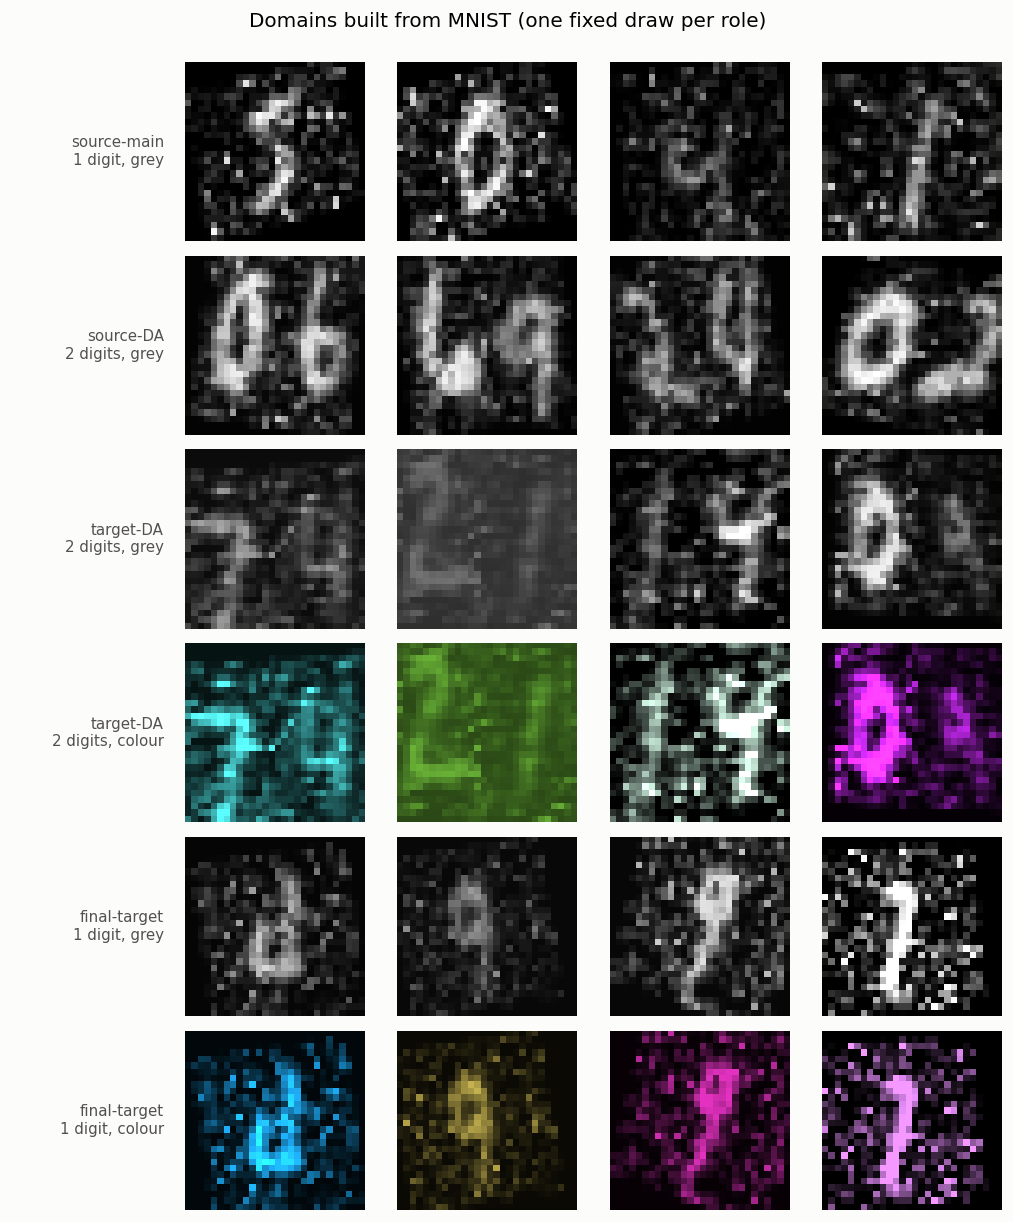

In [2]:
def example_args():
    return argparse.Namespace(
        augment=True, contrast=True, color=True,
        source_dirt=2.75, target_dirt=3.00, dirt_sigma=0.25,
        contrast_source_sigma=0.08, contrast_target_sigma=0.45,
        contrast_source_mean=1.0, contrast_target_mean=1.0,
        color_mode="global", color_alpha=0.90,
    )


def make_1digit(pool, mean, *, target, color, seed, n=4):
    args = example_args()
    generator = torch.Generator().manual_seed(seed)
    strengths = torch.full((n,), mean)
    base = toy.prepare_1digit_base(pool[:n], strengths, target=target,
                                   args=args, generator=generator)
    return toy.finish_domain_g(
        base, target=target, color=color, generator=generator,
        color_mode=args.color_mode, color_alpha=args.color_alpha)


def make_2digit(pool, mean, *, target, color, seed, n=4):
    args = example_args()
    generator = torch.Generator().manual_seed(seed)
    strengths = torch.full((n,), mean)
    base = toy.prepare_2digit_base(pool[:n], pool[n:2 * n], strengths,
                                   target=target, args=args,
                                   generator=generator)
    return toy.finish_domain_g(
        base, target=target, color=color, generator=generator,
        color_mode=args.color_mode, color_alpha=args.color_alpha)


train_x, train_y, test_x, test_y = toy.load_mnist(toy.DEFAULT_DATA)
task_pool = train_x[:8]
source_pool = train_x[8000:8008]
target_pool = test_x[:8]
final_pool = test_x[8000:8008]

rows = [
    ("source-main\n1 digit, grey",
     make_1digit(task_pool, 2.75, target=False, color=False, seed=11)),
    ("source-DA\n2 digits, grey",
     make_2digit(source_pool, 2.75, target=False, color=False, seed=12)),
    ("target-DA\n2 digits, grey",
     make_2digit(target_pool, 3.00, target=True, color=False, seed=13)),
    ("target-DA\n2 digits, colour",
     make_2digit(target_pool, 3.00, target=True, color=True, seed=13)),
    ("final-target\n1 digit, grey",
     make_1digit(final_pool, 3.00, target=True, color=False, seed=14)),
    ("final-target\n1 digit, colour",
     make_1digit(final_pool, 3.00, target=True, color=True, seed=14)),
]

fig = plt.figure(figsize=(8.6, 10.4))
grid = fig.add_gridspec(len(rows), 5,
                        width_ratios=[0.75, 1.0, 1.0, 1.0, 1.0],
                        hspace=0.08, wspace=0.05)
fig.subplots_adjust(top=0.94, bottom=0.02, left=0.02, right=0.99)
for row, (label, images) in enumerate(rows):
    label_ax = fig.add_subplot(grid[row, 0])
    label_ax.set_axis_off()
    label_ax.text(1.0, 0.5, label, transform=label_ax.transAxes,
                  ha="right", va="center", fontsize=9,
                  color=SECONDARY)
    for column in range(4):
        ax = fig.add_subplot(grid[row, column + 1])
        image = images[column].permute(1, 2, 0).numpy()
        ax.imshow(image, vmin=0.0, vmax=1.0, interpolation="nearest",
                  aspect="equal")
        ax.set_axis_off()
fig.suptitle("Domains built from MNIST (one fixed draw per role)",
             fontsize=12)
plt.show()

Rows 3–4 show the same target-DA images with and without colour; rows 5–6
do the same for the final target.  Colour is applied after the shared
dirt/augmentation pipeline, so it changes only the channel gains.  The
two-digit frames are built from two dirtied digits, cropped, concatenated
and resized to 28×28.

The grid below shows all ten classes clean and at source dirt 2.75, after
the same augmentations.

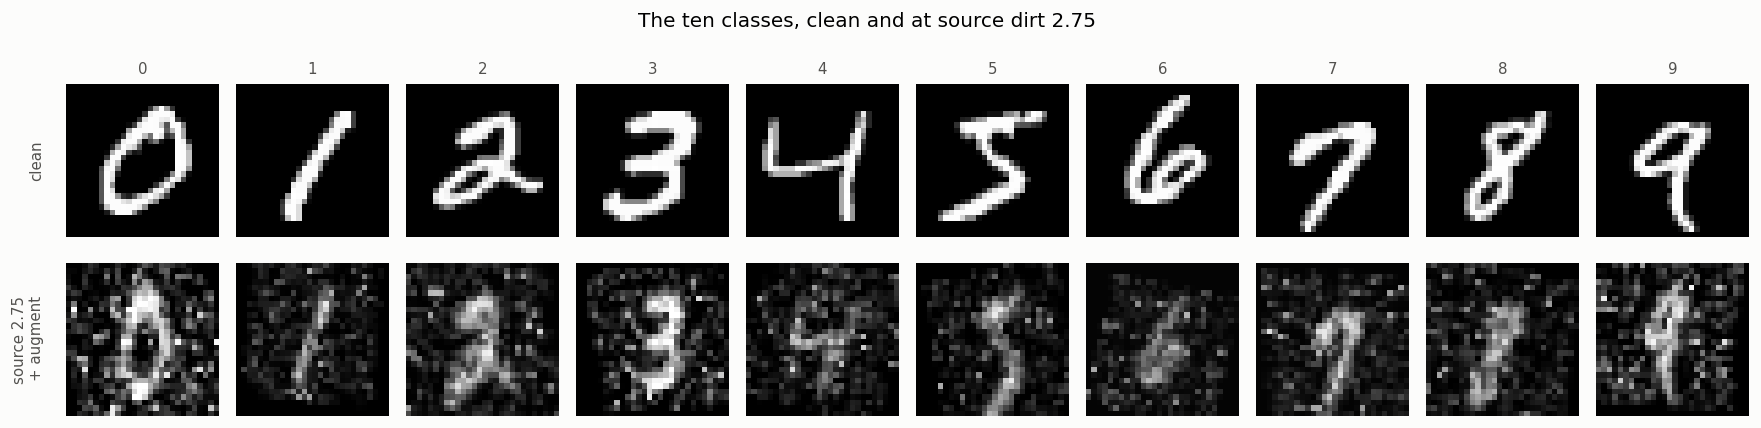

In [3]:
fig, axes = plt.subplots(2, 10, figsize=(15.0, 3.8))
for digit in range(10):
    index = int((train_y == digit).nonzero()[0])
    clean = train_x[index:index + 1]
    dirty = make_1digit(clean, 2.75, target=False, color=False,
                        seed=21 + digit, n=1)
    for row, image in enumerate((toy.gray_rgb(clean), dirty)):
        ax = axes[row, digit]
        ax.imshow(image[0].permute(1, 2, 0).numpy(), vmin=0.0, vmax=1.0,
                  interpolation="nearest")
        ax.set_axis_off()
    axes[0, digit].set_title(str(digit), fontsize=9, color=SECONDARY)
fig.suptitle("The ten classes, clean and at source dirt 2.75",
             fontsize=12)
fig.tight_layout()
fig.subplots_adjust(left=0.055)
for row, label in enumerate(("clean", "source 2.75\n+ augment")):
    box = axes[row, 0].get_position()
    fig.text(box.x0 - 0.012, (box.y0 + box.y1) / 2.0, label,
             ha="right", va="center", rotation=90, fontsize=9,
             color=SECONDARY)
plt.show()

## 2. How the domain adaptation works

The model is a DANN (domain-adversarial neural network).  One encoder
serves both the classification task and the domain critic:

```
source-DA batch (2 digits, grey)      target-DA batch (2 digits, coloured)
              \                                   /
               \___ shared encoder E(x) _________/
                              |
              ┌───────────────┴────────────────┐
      task head C(E(x))               domain critic D(GRL(E(x)))
      10-digit classification          source vs target
      labels from source-main          no class labels
              |                                |
       cross-entropy                  binary cross-entropy
```

- The classifier is trained on labelled one-digit source images.  The DA
  branch never uses class labels; it only sees the two unlabelled
  two-digit pools.
- The critic tries to separate source features from target features.  The
  gradient-reversal layer (GRL) multiplies the gradient reaching the
  encoder by −λ: the task loss pulls the encoder one way, while the
  reversed domain loss pushes it to make the two domains indistinguishable.
- The critic is trained harder than the encoder: five critic steps per
  encoder step, a separate optimiser, and a critic batch of 512.  Without
  this the critic would collapse as soon as the encoder moved.
- Schedule: one warm-up epoch with λ = 0 (critic only), then λ = 0.2 for
  the remaining nine epochs.  Nothing else in the loss depends on the
  domains.

In [4]:
x = torch.tensor([1.0, 2.0, 3.0], requires_grad=True)
y = toy.grl(x, 0.2)
y.sum().backward()
print("forward:  y =", y.detach().tolist())
print("backward: dL/dx =", x.grad.tolist(),
      " (upstream gradient 1, reversed and scaled by lambda)")

encoder = toy.Encoder()
classifier = toy.Classifier(encoder.out_dim)
critic = toy.DomainDiscriminator(encoder.out_dim, hidden=128, norm=True)


def n_params(module):
    return sum(p.numel() for p in module.parameters())


print(f"encoder {n_params(encoder):,} params; "
      f"classifier {n_params(classifier):,}; "
      f"critic {n_params(critic):,}")

forward:  y = [1.0, 2.0, 3.0]
backward: dL/dx = [-0.20000000298023224, -0.20000000298023224, -0.20000000298023224]  (upstream gradient 1, reversed and scaled by lambda)
encoder 23,808 params; classifier 5,770; critic 91,649


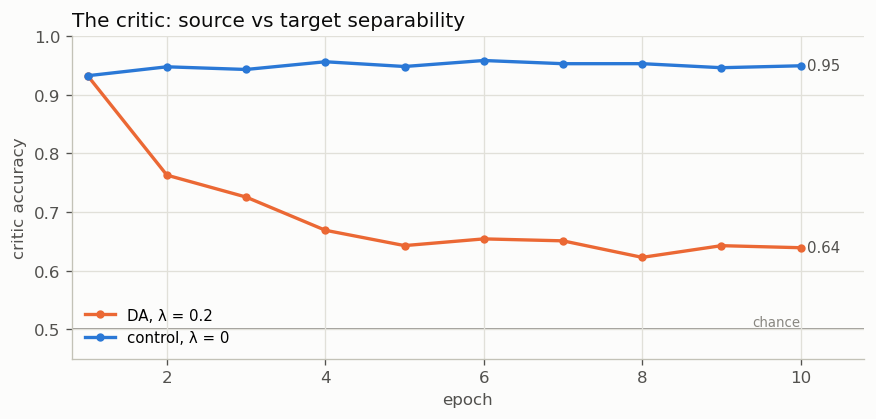

In [5]:
fig, ax = plt.subplots(figsize=(7.4, 3.6))
ax.plot(epochs, da["critic_history"], color=ORANGE, marker="o", ms=4,
        label="DA, λ = 0.2")
ax.plot(epochs, control["critic_history"], color=BLUE, marker="o", ms=4,
        label="control, λ = 0")
ax.axhline(0.5, color=MUTED, lw=1.0, zorder=0)
ax.text(epochs[-1], 0.5, "chance", color=MUTED, fontsize=8,
        ha="right", va="bottom")
ax.set_ylim(0.45, 1.0)
ax.set_xlim(epochs[0] - 0.2, epochs[-1] + 0.8)
ax.set_xlabel("epoch")
ax.set_ylabel("critic accuracy")
ax.set_title("The critic: source vs target separability", loc="left")
ax.legend(loc="lower left", fontsize=9)
for values in (da["critic_history"], control["critic_history"]):
    ax.annotate(f"{values[-1]:.2f}", (epochs[-1], values[-1]),
                xytext=(4, 0), textcoords="offset points",
                va="center", fontsize=9, color=SECONDARY)
fig.tight_layout()
plt.show()

The control keeps the critic trained but never sends its gradient to the
encoder (λ = 0): the critic stays around 0.95, so the colour is still
fully readable.  With the adversarial term it falls to 0.64 — the encoder
has removed much of the domain signal.  It does not reach 0.5: the
domains remain partly separable, which is expected because the colour is
real and the features still have to support the ten-digit task.

## 3. What the DA changes on the target domain

All numbers below are on held-out data, never used for training:

- **source-test accuracy** — ten-class accuracy on one-digit source images;
- **final-target accuracy** — ten-class accuracy on one-digit coloured
  images from MNIST test, averaged over three fixed draws per image;
- **probe1 / probe2** — AUC of a fresh logistic regression on frozen
  encoder features, separating source from target, for one-digit and
  two-digit images respectively.  0.5 means the domains are
  indistinguishable;
- **paired colour probe** — AUC separating the *same* target images with
  and without colour.  0.5 means the colour is gone;
- **critic** — the domain critic's accuracy at the end of training.

Representative run: colour line, seed 0, 10 epochs, λ = 0.2.

In [6]:
rows = [
    ("source-test accuracy", baseline["source"], da["source"]),
    ("final-target accuracy", baseline["target"], da["target"]),
    ("probe1, one-digit (AUC)", baseline["probe1"], da["probe1"]),
    ("probe2, two-digit (AUC)", baseline["probe2"], da["probe2"]),
    ("paired colour probe (AUC)",
     baseline["probe_color"], da["probe_color"]),
]
lines = [
    "| metric | baseline | DA (λ = 0.2) | change |",
    "|---|---:|---:|---:|",
]
for name, before, after in rows:
    lines.append(f"| {name} | {before:.3f} | {after:.3f} | "
                 f"{100 * (after - before):+.2f} pp |")
lines.append(f"| critic accuracy (two-digit) | — | "
             f"{da['critic_final']:.3f} | — |")
display(Markdown("\n".join(lines)))

| metric | baseline | DA (λ = 0.2) | change |
|---|---:|---:|---:|
| source-test accuracy | 0.867 | 0.871 | +0.43 pp |
| final-target accuracy | 0.778 | 0.857 | +7.88 pp |
| probe1, one-digit (AUC) | 0.930 | 0.787 | -14.29 pp |
| probe2, two-digit (AUC) | 0.932 | 0.769 | -16.21 pp |
| paired colour probe (AUC) | 0.893 | 0.738 | -15.41 pp |
| critic accuracy (two-digit) | — | 0.639 | — |

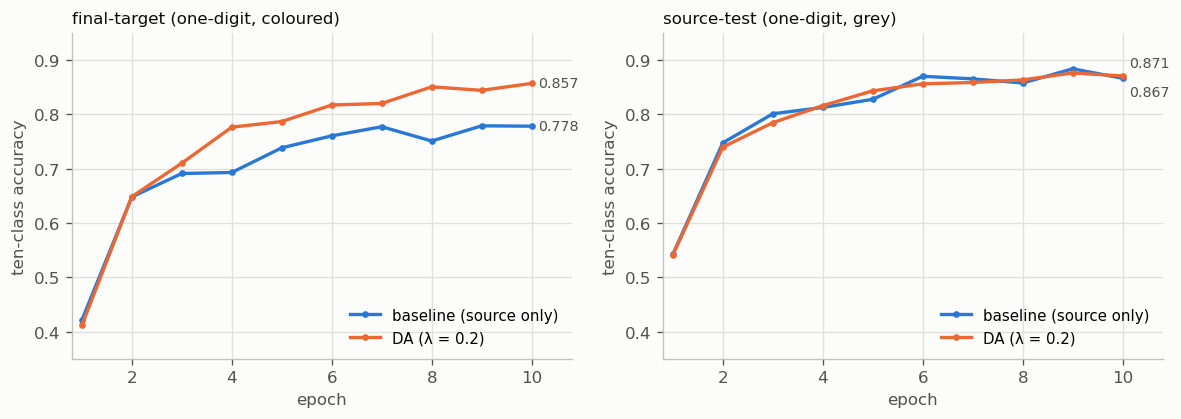

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.6))
panels = [
    ("target_history", "final-target (one-digit, coloured)"),
    ("source_history", "source-test (one-digit, grey)"),
]
for ax, (key, title) in zip(axes, panels):
    ax.plot(epochs, baseline[key], color=BLUE, marker="o", ms=3,
            label="baseline (source only)")
    ax.plot(epochs, da[key], color=ORANGE, marker="o", ms=3,
            label="DA (λ = 0.2)")
    ax.set_title(title, loc="left", fontsize=10)
    ax.set_xlabel("epoch")
    ax.set_ylabel("ten-class accuracy")
    ax.set_ylim(0.35, 0.95)
    ax.set_xlim(epochs[0] - 0.2, epochs[-1] + 0.8)
    ax.legend(loc="lower right", fontsize=9)
    dy = 0 if key == "target_history" else 8
    for values, offset in ((baseline[key], -dy), (da[key], dy)):
        ax.annotate(f"{values[-1]:.3f}", (epochs[-1], values[-1]),
                    xytext=(4, offset), textcoords="offset points",
                    va="center", fontsize=8.5, color=SECONDARY)
fig.tight_layout()
plt.show()

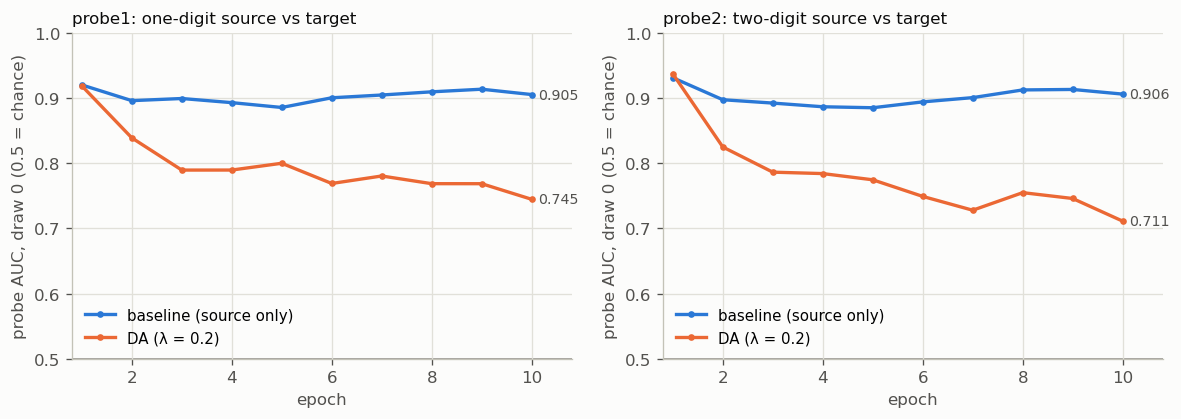

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(10.0, 3.6))
panels = [
    ("probe1_history", "probe1: one-digit source vs target"),
    ("probe2_history", "probe2: two-digit source vs target"),
]
for ax, (key, title) in zip(axes, panels):
    ax.plot(epochs, baseline[key], color=BLUE, marker="o", ms=3,
            label="baseline (source only)")
    ax.plot(epochs, da[key], color=ORANGE, marker="o", ms=3,
            label="DA (λ = 0.2)")
    ax.axhline(0.5, color=MUTED, lw=1.0, zorder=0)
    ax.set_ylim(0.5, 1.0)
    ax.set_xlim(epochs[0] - 0.2, epochs[-1] + 0.8)
    ax.set_xlabel("epoch")
    ax.set_ylabel("probe AUC, draw 0 (0.5 = chance)")
    ax.set_title(title, loc="left", fontsize=10)
    ax.legend(loc="lower left", fontsize=9)
    for values in (baseline[key], da[key]):
        ax.annotate(f"{values[-1]:.3f}", (epochs[-1], values[-1]),
                    xytext=(4, 0), textcoords="offset points",
                    va="center", fontsize=8.5, color=SECONDARY)
fig.tight_layout()
plt.show()

In this run the DA raises the final-target accuracy from 0.778 to 0.857
(+7.9 pp) and leaves the source accuracy at 0.867–0.871.  The
source-to-target gap shrinks from 8.8 pp to 1.4 pp.

At the same time the domain probes fall: probe1 from 0.930 to 0.787,
probe2 from 0.932 to 0.769, and the paired colour probe from 0.893 to
0.738.  The encoder has not erased the domains — 0.5 is not reached — but
it keeps much less information that is specific to them.  Per-epoch
probes use one draw; the final values in the table use all three.

In [9]:
def load_runs(pattern):
    return [json.loads(path.read_text())["runs"][0]
            for path in sorted((ROOT / "runs").glob(pattern))]


def mean_std(values):
    array = np.asarray(values, dtype=float)
    return float(array.mean()), float(array.std(ddof=1))


def table_row(label, runs, block):
    source = mean_std([r[block]["source"] for r in runs])
    target = mean_std([r[block]["target"] for r in runs])
    probe1 = mean_std([r[block]["probe1"] for r in runs])
    probe2 = mean_std([r[block]["probe2"] for r in runs])
    if block == "baseline":
        delta = "—"
    else:
        gaps = [r[block]["target"] - r["baseline"]["target"]
                for r in runs]
        gap_mean, gap_std = mean_std(gaps)
        delta = f"{100 * gap_mean:+.2f} ± {100 * gap_std:.2f}"
    colours = [r[block].get("probe_color") for r in runs]
    colour_text = ("—" if any(c is None for c in colours) else
                   "{:.3f} ± {:.3f}".format(*mean_std(colours)))
    critics = [r[block].get("critic_final") for r in runs]
    critic_text = ("—" if any(c is None for c in critics) else
                   "{:.3f} ± {:.3f}".format(*mean_std(critics)))
    return (f"| {label} | {source[0]:.3f} ± {source[1]:.3f} | "
            f"{target[0]:.3f} ± {target[1]:.3f} | {delta} | "
            f"{probe1[0]:.3f} ± {probe1[1]:.3f} | "
            f"{probe2[0]:.3f} ± {probe2[1]:.3f} | "
            f"{colour_text} | {critic_text} |")


colour_runs = load_runs("main_color_l02_s*.json")
colour0_runs = load_runs("main_color_l00_s*.json")
nocolour_runs = load_runs("main_nocolor_l02_s*.json")
nocolour0_runs = load_runs("main_nocolor_l00_s*.json")

lines = [
    "| scenario | source | final target | Δ target (pp) | probe1 "
    "| probe2 | paired colour | critic |",
    "|---|---:|---:|---:|---:|---:|---:|---:|",
    table_row("colour, baseline", colour_runs, "baseline"),
    table_row("colour, DA λ = 0.2", colour_runs, "surrogate_da"),
    table_row("colour, DA λ = 0", colour0_runs, "surrogate_da"),
    table_row("no colour, baseline", nocolour_runs, "baseline"),
    table_row("no colour, DA λ = 0.2", nocolour_runs, "surrogate_da"),
    table_row("no colour, DA λ = 0", nocolour0_runs, "surrogate_da"),
]
display(Markdown("\n".join(lines)))
print("five seeds per row; Δ target is paired within seed")

| scenario | source | final target | Δ target (pp) | probe1 | probe2 | paired colour | critic |
|---|---:|---:|---:|---:|---:|---:|---:|
| colour, baseline | 0.873 ± 0.006 | 0.759 ± 0.022 | — | 0.919 ± 0.009 | 0.928 ± 0.004 | 0.880 ± 0.013 | — |
| colour, DA λ = 0.2 | 0.868 ± 0.006 | 0.841 ± 0.011 | +8.19 ± 2.16 | 0.810 ± 0.016 | 0.800 ± 0.019 | 0.750 ± 0.018 | 0.669 ± 0.019 |
| colour, DA λ = 0 | 0.870 ± 0.008 | 0.761 ± 0.023 | +0.17 ± 2.07 | 0.921 ± 0.008 | 0.929 ± 0.006 | 0.882 ± 0.009 | 0.950 ± 0.006 |
| no colour, baseline | 0.873 ± 0.006 | 0.858 ± 0.016 | — | 0.703 ± 0.008 | 0.732 ± 0.009 | — | — |
| no colour, DA λ = 0.2 | 0.874 ± 0.008 | 0.878 ± 0.009 | +2.03 ± 1.81 | 0.677 ± 0.007 | 0.689 ± 0.006 | — | 0.564 ± 0.017 |
| no colour, DA λ = 0 | 0.874 ± 0.007 | 0.860 ± 0.015 | +0.24 ± 0.62 | 0.708 ± 0.010 | 0.734 ± 0.011 | — | 0.777 ± 0.016 |

five seeds per row; Δ target is paired within seed


Across five seeds the colour line gains **+8.19 ± 2.16 pp** on the final
target, while the source accuracy stays within 0.5 pp.  The two controls
isolate the cause:

- training the critic but setting λ = 0 leaves the target at
  **+0.17 ± 2.07 pp** — domain exposure alone does nothing;
- removing the colour makes the target easier and reduces the gain to
  **+2.03 ± 1.81 pp**, so the large effect is specific to the new feature,
  not to "DA helps".

The paired colour probe falls from 0.880 to 0.750 on average, and the
critic ends at 0.669, against 0.950 in the λ = 0 control.  The removal is
substantial but partial, consistent with the remaining gap to the
target-supervised calibration model (0.873, one seed, last-two-epoch
mean).

This table uses the final epoch and the final K = 3 probes, the same
convention as the single-run table above.  `README.md` quotes the mean of
the last three epochs; its colour-line gain is therefore +8.60 ± 1.77 pp
rather than +8.19 ± 2.16 pp here.  Both are computed from the same runs.

## 4. Takeaway

- DA recovers most of the source-to-target accuracy loss caused by a
  target-only feature (colour), while leaving source accuracy unchanged.
- The gain is adversarial: with λ = 0 the critic is trained but nothing
  propagates to the encoder, and the target accuracy does not move.
- The domain information is reduced but not erased: the probes stay above
  0.5 and the paired colour probe stays around 0.74.  The residual is
  visible as the gap to a target-supervised model.
- Without the new feature (no-colour control) the target is easier and the
  DA gain is small (+2.5 pp), so the result is not "DA always helps".
- This is a surrogate: colour/contrast stands in for a real
  geometry/event-length feature, and MNIST does not reproduce the
  detector.  See the *Baikal analogy* section of `README.md`.

## Provenance

- `toy_da.py` — data, augmentation, colour, DANN, probes.
- `runs/main_color_l02_s0.json` — the representative run shown here.
- `runs/main_color_l00_s0.json` — the λ = 0 control.
- `runs/main_{color,nocolor}_l{00,02}_s*.json` — the five-seed table.
- All figures in this notebook are generated from the cells above, using
  the same helpers as `toy_da.py`; no stored image files are read.
- Full design, calibration and caveats: `README.md`.